# Fig. 6 — sensitivity from polymer bistability

> Type set for PNAS (`pnas-new`): 8 pt text, 7 pt tick labels, 10 pt panel letters as printed. Writes `fig6/fig6.pdf`. The previous layout is kept in `../alt/fig6/`.

Draws the figure from `processed_data/` and saves `fig6/fig6.pdf`.
See `figure_production/README.md` to regenerate the data.

In [1]:
import os

# Reads processed_data/... and art_*.svg relative to figure_production/. Find
# that directory rather than assume the kernel started in it.
DIR_OVERRIDE = None     # set to figure_production's path to skip the search

_SKIP = {"node_modules", "__pycache__", "venv", ".venv", "env", "build", "dist"}


def _ok(d):
    return (os.path.isfile(os.path.join(d, "README.md"))
            and os.path.isdir(os.path.join(d, "processed_data")))


def resolve_figdir():
    if DIR_OVERRIDE:
        if not _ok(DIR_OVERRIDE):
            raise RuntimeError("DIR_OVERRIDE is not figure_production/: " + DIR_OVERRIDE)
        return DIR_OVERRIDE
    starts = []
    nb = globals().get("__vsc_ipynb_file__") or globals().get("__file__")
    if nb:
        starts.append(os.path.dirname(os.path.abspath(nb)))
    starts.append(os.path.abspath(os.getcwd()))
    for start in starts:                      # at or above
        d = start
        for _ in range(6):
            if _ok(d):
                return d
            parent = os.path.dirname(d)
            if parent == d:
                break
            d = parent
    level = [os.path.abspath(os.getcwd())]    # or below, shallowest first
    for _ in range(4):
        nxt = []
        for d in level:
            try:
                names = sorted(os.listdir(d))
            except OSError:
                continue
            for name in names:
                if name.startswith(".") or name in _SKIP:
                    continue
                cand = os.path.join(d, name)
                if not os.path.isdir(cand) or os.path.islink(cand):
                    continue
                if _ok(cand):
                    return cand
                nxt.append(cand)
        level = nxt
    raise RuntimeError(
        "figure_production/ not found from %s -- expected a directory holding "
        "README.md and processed_data/. Set DIR_OVERRIDE above and re-run."
        % os.getcwd())


os.chdir(resolve_figdir())
print("working directory:", os.getcwd())

working directory: /Users/tmora/NextCloudCNRS/Code/droplet/prewet-gene/figure_production


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt


def use_latex():
    plt.rcParams.update({"text.usetex": True, "font.family": "serif",
                         "text.latex.preamble": r"\usepackage{amsmath}"})
    try:
        f = plt.figure()
        f.text(0.5, 0.5, r"$\dfrac{U_{\rm tot}}{k_BT}$ $d^{\rm x}$")
        f.canvas.draw()
        plt.close(f)
        return True
    except Exception as exc:
        plt.close("all")
        # Computer Modern via matplotlib's bundled cmr10, so text widths match
        # the LaTeX render closely (layout checks only)
        plt.rcParams.update({"text.usetex": False, "font.family": "serif",
                             "font.serif": ["cmr10"], "mathtext.fontset": "cm",
                             "axes.formatter.use_mathtext": True})
        print("LaTeX unavailable, falling back to mathtext:",
              type(exc).__name__, str(exc).strip()[:120])
        return False


USETEX = use_latex()
print("usetex:", USETEX)

usetex: True


In [3]:
DATA = "processed_data"
S = json.load(open(os.path.join(DATA, "fig6_scalars.json")))
_rd = lambda name: pd.read_csv(os.path.join(DATA, name), float_precision="round_trip")
A_DAT, B_DAT = _rd("fig6_a.csv"), _rd("fig6_b.csv")
EF = _rd("fig6_ef.csv")
VC = _rd("fig6_vs_c.csv")          # C, D and the Fisher rates vs c
VS = _rd("fig6_vs_s.csv")          # Fisher rates vs s, low_c and high_c
print("A at c/c_sat = %(low).3f, %(high).3f;" % S["A"], "B at %(low).3f, %(high).3f" % S["B"])
print("vs s at c/c_sat =", {k: round(v, 3) for k, v in S["IJ_c_over_csat"].items()},
      " s* =", {k: round(v, 2) for k, v in S["s_star"].items()})

A at c/c_sat = 0.127, 0.895; B at 0.127, 0.950
vs s at c/c_sat = {'low_c': 0.155, 'high_c': 0.429}  s* = {'low_c': 83.74, 'high_c': 91.31}


In [4]:
# PNAS (pnas-new, 9pt): \textwidth = 505.69 TeX pt = 504.0 bp, so a figure built
# 481.9 pt wide is printed 1.0459x larger. The geometry is in built points
# and the type is set so that the PRINTED sizes are 8 pt text,
# 7 pt tick labels and 10 pt panel letters.
PNAS_W, BUILT_W = 504.0, 481.9
PRINT = PNAS_W / BUILT_W
PT_CAPTION, PT_TICK, PT_LETTER = 8 / PRINT, 7 / PRINT, 10 / PRINT
LW, LW_AUX, LW_AXES = 0.5, 0.4, 0.5            # strokes, printed pt

LETTER = {"A": "A", "B": "B", "C": "C", "D": "D", "H": "E", "E": "F", "F": "G", "I": "H", "J": "I"}

# Layout (the user's sketch): a top row of four squares A-D, each 0.25 of the
# width; a bottom row 0.35 of the width tall: E (0.35 of the width), F over G
# (0.3), H over I (0.35). Widths are whole cells, y label and margins included.
W = 481.9                                      # \textwidth, points
PAD = 12.0                                     # page top: the first row's letters
XLAB = 18.0                                    # tick labels + x label under a plot
TITLE = 12.0                                   # a panel title above a plot (letter beside it)
ROW_GAP = 4.0 + 3 * 72 / 25.4                  # between the rows, besides XLAB and TITLE: 3 mm of breathing space
LM, RM = 41.0, 2.0                             # cell margins: 2-line y label + ticks; right

TOP_X = [f * W for f in (0.0, 0.25, 0.5, 0.75)]           # A, B, C, D
E_X, FG_X, HI_X = 0.0, 0.35 * W, 0.65 * W                 # bottom row cells
SQ = 0.25 * W - LM - RM                                   # side of the squares A-D

# y measured downwards from the page top
TOP_T = PAD
TOP_B = TOP_T + SQ
BOT_T = TOP_B + XLAB + ROW_GAP + TITLE                    # bottom row: plot tops (letters/titles above)
BOT_H = 0.35 * W - XLAB - TITLE                           # the row is 0.35 W tall, labels included
BOT_B = BOT_T + BOT_H
STACK_GAP = TITLE + 2.0                                   # between stacked plots: the lower one's title
STACK_H = (BOT_H - STACK_GAP) / 2                         # F, G and H, I each
H = BOT_B + XLAB + 3.0                                    # page height

CB_W, CB_PAD, CB_LAB = 5.0, 4.0, 15.0                     # F/G colour bar: bar, gap, tick labels (title on top)
E_W = 0.35 * W - LM - RM
FG_W = 0.30 * W - LM - CB_PAD - CB_W - CB_LAB
HI_W = 0.35 * W - LM - RM


def box(x0, x1, top, bot):
    """Figure-fraction rect of a plot spanning x0..x1, top..bot (y from the page top)."""
    return [x0 / W, 1 - bot / H, (x1 - x0) / W, (bot - top) / H]


RC = {
    "font.size": PT_CAPTION, "axes.labelsize": PT_CAPTION,
    "axes.titlesize": PT_CAPTION, "legend.fontsize": PT_CAPTION,
    "xtick.labelsize": PT_TICK, "ytick.labelsize": PT_TICK,
    "lines.linewidth": LW, "axes.linewidth": LW_AXES,
    "xtick.major.width": LW_AXES, "ytick.major.width": LW_AXES,
    "xtick.minor.width": LW_AUX, "ytick.minor.width": LW_AUX,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "xtick.minor.size": 1.5, "ytick.minor.size": 1.5,
    "axes.labelpad": 1.5, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5,
    "axes.titlepad": 3.0,
    "legend.frameon": False, "legend.borderaxespad": 0.3, "legend.handlelength": 1.6,
    "legend.handletextpad": 0.5, "legend.labelspacing": 0.25,
}

C_CLOSED, C_CYCLE = "green", "C4"
C_PROX, C_POLY, C_TOTAL = "red", "blue", "black"
CMAP = mpl.cm.viridis
X_TICKS_C = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])

print("figure %.1f x %.1f pt = %.3f x %.3f in" % (W, H, W / 72, H / 72))

figure 481.9 x 291.6 pt = 6.693 x 4.051 in


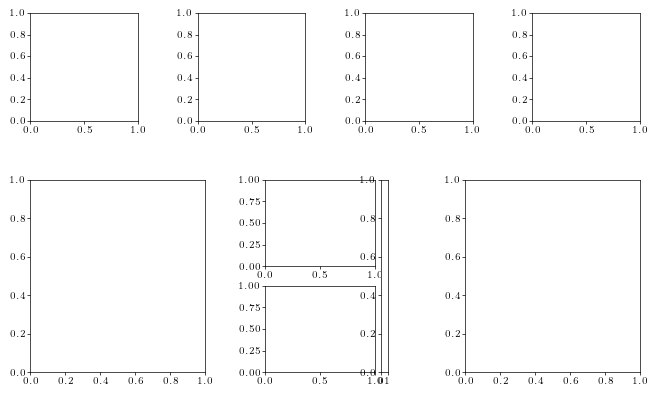

In [5]:
plt.rcParams.update(RC)
fig6 = plt.figure(figsize=(W / 72, H / 72))

aA, aB, aC, aD = (fig6.add_axes(box(x + LM, x + LM + SQ, TOP_T, TOP_B)) for x in TOP_X)
aH = fig6.add_axes(box(E_X + LM, E_X + LM + E_W, BOT_T, BOT_B))             # Fisher rate vs c (E)
aE = fig6.add_axes(box(FG_X + LM, FG_X + LM + FG_W, BOT_T, BOT_T + STACK_H))  # escape (F)
aF = fig6.add_axes(box(FG_X + LM, FG_X + LM + FG_W, BOT_B - STACK_H, BOT_B), sharex=aE)  # return (G)
x_cb = FG_X + LM + FG_W + CB_PAD
aCB = fig6.add_axes(box(x_cb, x_cb + CB_W, BOT_T, BOT_B))
aI = fig6.add_axes(box(HI_X + LM, HI_X + LM + HI_W, BOT_T, BOT_B))         # vs s, both concentrations (H)

In [6]:
ab_norm = plt.Normalize(*S["AB_colour_range"])
for tag, label in (("low", "0.1"), ("high", "0.9")):
    aA.plot(A_DAT.d_nm, A_DAT["phi_local_" + tag], color=CMAP(ab_norm(S["A"][tag])))
    aB.plot(B_DAT.d_nm, B_DAT["force_" + tag], color=CMAP(ab_norm(S["B"][tag])),
            label=label)
aA.set_xlim(80, 100); aA.set_ylim(0, 0.13)
aA.set_xlabel(r"Distance $d$ (nm)")
aA.set_ylabel("Probe vol. fraction\n" + r"$\phi_{\rm local}(c, d)$")
aB.set_xlim(80, 100)
aB.set_xlabel(r"Distance $d$ (nm)")
aB.set_ylabel(r"Force $F_{\rm attr}(d)$" + "\n" + r"($k_BT$/nm)")
aB.legend(loc="lower right", title=r"$c/c_{\rm sat}$", handlelength=1.2)   # narrow: clear of the curves
for ax in (aA, aB):
    ax.set_xticks([80, 90, 100])

In [7]:
an = VC[VC.analysed == 1]                       # concentrations with enough cycles
c = an.c_over_csat
aC.plot(c, an.p_closed, color=C_CLOSED)
aC.fill_between(c, an.p_closed - an.p_closed_se, an.p_closed + an.p_closed_se,
                color=C_CLOSED, alpha=0.25, lw=0)
aC.plot(c, an.p_free, color="black", ls="dashed")
aC.axhline(0.5, lw=LW_AUX, color="black", alpha=0.4)
aC.set_ylabel("Probability")
aC.set_ylim(-0.05, 1.05); aC.set_yticks([0.0, 0.5, 1.0])
# a legend would be wider than the square: label the curves in their empty corners
aC.text(0.04, 0.96, "polymer closed", color=C_CLOSED, transform=aC.transAxes, ha="left", va="top")
aC.text(0.97, 0.04, "free receptor on", color="black", transform=aC.transAxes, ha="right", va="bottom")
aC.plot([0.05, 0.17], [0.075, 0.075], transform=aC.transAxes, color="black", ls="dashed", lw=LW)  # line sample, left of its label
aC.set_xlabel(r"Concentration $c/c_{\rm sat}$")

aD.plot(c, an.cycle_time, color=C_CYCLE, label=r"$\tau_{p}$")
aD.fill_between(c, an.cycle_time - an.cycle_time_se, an.cycle_time + an.cycle_time_se,
                color=C_CYCLE, alpha=0.25, lw=0)
aD.plot(c, an.tau_free, color="black", ls="dashed", label=r"$\tau_{r}$")
aD.set_yscale("log")
aD.set_ylabel("Cycle time (s)")
aD.set_xlabel(r"Concentration $c/c_{\rm sat}$")
aD.legend(loc="upper left")
xt = X_TICKS_C[X_TICKS_C <= c.max() + 0.05][::2]   # no ticks beyond the analysed range; every 0.2 in a small square
for ax in (aC, aD):
    ax.set_xticks(xt); ax.set_xticklabels(["%g" % v for v in xt])

In [8]:
pt = an[np.isfinite(an.polymer_fit)]
tt = an[np.isfinite(an.total_fit)]
aH.plot(c, an.rate_open, color=C_PROX, label="Proximal only")
aH.plot(pt.c_over_csat, pt.polymer_fit, color=C_POLY, label="Polymer only")
aH.fill_between(pt.c_over_csat, pt.polymer_lo, pt.polymer_hi, color=C_POLY, alpha=0.2, lw=0)
aH.plot(tt.c_over_csat, tt.total_fit, color=C_TOTAL, label="Proximal + distal")
aH.fill_between(tt.c_over_csat, tt.total_lo, tt.total_hi, color=C_TOTAL, alpha=0.2, lw=0)
aH.plot(c, an.rate_free, color="black", ls="dashed", label="Free receptor")
aH.set_ylim(0, 120)
aH.set_ylabel("Fisher info. rate (bits/s)")    # as the vs-s panels
aH.set_xlabel(r"Concentration $c/c_{\rm sat}$")
aH.set_xticks(xt); aH.set_xticklabels(["%g" % v for v in xt])
aH.set_xlim(*aD.get_xlim())
aH.legend(loc="upper left")

In [9]:
ef_norm = plt.Normalize(S["EF"]["c_over_csat_min"], S["EF"]["c_over_csat_max"])
for ax, channel, title in ((aE, "escape", "Escape time"), (aF, "return", "Return time")):
    sub = EF[EF.channel == channel]
    for cc, g in sub.groupby("c_over_csat"):
        ax.plot(g.t, g.pdf, color=CMAP(ef_norm(cc)), alpha=0.6)
    ax.set_title(title)
    ax.set_yscale("log")
    ax.set_xlim(-0.1, 2)
    ax.set_ylabel("PDF")
aF.set_xticks([0, 1, 2])
aF.set_xlabel("Time (s)")
aE.tick_params(labelbottom=False)               # stacked: one time axis, under G
aE.set_yticks([1e-2, 1e0, 1e2])
aF.set_yticks([1e-3, 1e-1, 1e1, 1e3])
for ax in (aE, aF):
    ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
cb = fig6.colorbar(mpl.cm.ScalarMappable(norm=ef_norm, cmap=CMAP), cax=aCB)
aCB.set_title(r"$c/c_{\rm sat}$", pad=3, loc="left")   # short: clear of the H/I letters
cb.outline.set_linewidth(LW_AXES)

In [10]:
# ---- H: full Fisher rate vs genomic separation, one colour per concentration ------
# (the original I and J merged; only proximal + distal is kept). Colours from F/G's
# concentration scale; s* dashed in the same colour.
for cond in ("low_c", "high_c"):
    d = VS[VS.condition == cond]
    tr = d[np.isfinite(d.polymer_fit)]
    cc = S["IJ_c_over_csat"][cond]
    col = CMAP(ef_norm(cc))
    aI.plot(tr.s, tr.polymer_fit + tr.rate_local, color=col, label=r"$c/c_{\rm sat} = %.2f$" % cc)
    aI.fill_between(tr.s, tr.rate_local + tr.polymer_lo - tr.rate_local_se,
                    tr.rate_local + tr.polymer_hi + tr.rate_local_se, color=col, alpha=0.2, lw=0)
    aI.axvline(S["s_star"][cond], color=col, ls="dashed", lw=LW)
aI.plot([], [], color="gray", ls="dashed", lw=LW, label=r"$s^*$")   # legend entry for the s* lines
aI.set_ylim(0, 95)
aI.set_yticks([0, 20, 40, 60, 80])
aI.set_xticks([100, 200, 300, 400, 500, 600])
aI.set_xlabel(r"Genomic separation $s$")
aI.set_ylabel("Fisher info. rate (bits/s)")
aI.legend(loc="center right")              # between the two curves, clear of the s* lines

In [11]:
# ---- panel letters -------------------------------------------------------------
# top-left of each cell: A-D at the page top, above their squares; E, F, H on the
# title line above the bottom row; G and I on their own title lines between the
# stacked plots
LX = 1.0
for orig, x, y in (("A", TOP_X[0] + LX, 1.0), ("B", TOP_X[1] + LX, 1.0),
                   ("C", TOP_X[2] + LX, 1.0), ("D", TOP_X[3] + LX, 1.0),
                   ("H", E_X + LX, BOT_T - TITLE - 1.0), ("E", FG_X + LX, BOT_T - TITLE - 1.0),
                   ("F", FG_X + LX, BOT_B - STACK_H - TITLE - 1.0),
                   ("I", HI_X + LX + 8.0, BOT_T - TITLE - 1.0)):      # H: clear of the colour bar's title
    fig6.text(x / W, 1 - y / H, LETTER[orig], usetex=False, fontfamily="Arial",
              fontsize=PT_LETTER, ha="left", va="top")

In [12]:
# ---- save --------------------------------------------------------------------------
path = os.path.join("fig6", "fig6.pdf")
fig6.savefig(path, format="pdf")                # no bbox_inches: keep \textwidth
print("Saved figure to", path)
try:
    from pypdf import PdfReader
    box_ = PdfReader(path).pages[0].mediabox
    print("page %.1f x %.1f pt" % (float(box_.width), float(box_.height)))
except ImportError:
    pass

Saved figure to fig6/fig6.pdf
page 481.9 x 291.6 pt


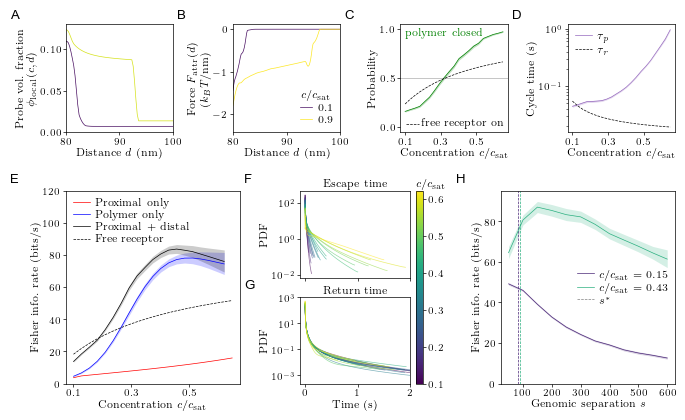

In [13]:
# The figure is created in one cell and drawn across several, so Jupyter never
# auto-displays it (the inline backend only shows figures created in the cell
# being run). Display it explicitly.
from IPython.display import display
display(fig6)